# Copy this notebook into usr/ and adjust to your needs.

In [1]:
%load_ext autoreload
%autoreload 2
import warnings
warnings.filterwarnings('ignore')

In [79]:
### setup ###

import sys
import random
import pandas as pd
# setup path to python virtual env & code directory
ecf_env_path = '/Users/kszczepaniak/Code/ecf-explorer-env'
lib_ecf_path = ecf_env_path + '/ecf-explorer/src'
sys.path.append(lib_ecf_path)

from utils.postprocess import load_clustering_results, select_reprseqs_to_display 
from utils.postprocess import load_features_data, select_features_to_display
from plots.plot_clustering_and_ecfs import plot_alignment_selected_families

workdir_path = '/Users/kszczepaniak/Data/Phage/phage-pp-workdir-ecftest-300'

In [43]:
# load dataset of hits with annotated clusters

clustering_results = load_clustering_results(workdir_path, mode='clusters')
clustering_results

,qname,qstart,qend,qlength,sname,sstart,send,slength,pident,bitscore,eval,prob,pval,cluster
0,reprseq30989,61,260,261,reprseq17791,43,198,200,19,108.2,1.200000e-12,98.7,1.900000e-16,0
1,reprseq30989,61,257,261,reprseq25394,60,214,215,16,115.8,1.700000e-13,98.9,2.700000e-17,0
2,reprseq30989,61,249,261,reprseq33575,43,210,217,16,70.4,2.200000e-06,96.7,3.400000e-10,0
3,reprseq30989,61,260,261,reprseq16961,43,216,218,15,108.0,2.000000e-12,98.7,3.200000e-16,0
4,reprseq30989,61,260,261,reprseq29975,45,231,233,12,107.4,3.400000e-12,98.6,5.500000e-16,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
652820,reprseq35525,5,480,488,reprseq31745,3,457,487,23,590.9,4.200000e-72,100.0,6.400000e-76,0
652821,reprseq35525,5,467,488,reprseq18132,2,527,527,23,1126.4,6.000000e-140,100.0,9.000000e-144,0
652822,reprseq35525,6,466,488,reprseq21544,3,475,476,42,985.6,4.000000e-123,100.0,6.000000e-127,0
652823,reprseq35525,7,418,488,reprseq29665,18,412,432,15,321.6,1.900000e-37,100.0,2.900000e-41,0


In [44]:
# load features data
# features_to_load = ['hhblits-pfam', 'hhblits-uniclust', 'hhblits-phrogs', 'hhrepid']
features_to_load = []

features_data = load_features_data(workdir_path, features_to_load)
for fname, fdata in features_data.items():
    print(fname)
    display(fdata)

In [45]:
# filter clustering results with prob/pident etc

In [46]:
# get mapping of taxo-families:genome:reprseq
# - need: name_table.txt, metadata.csv

input_dir = workdir_path + '/ecf-explorer/input/'
name_table = pd.read_csv(input_dir + 'name-table.txt')
name_table['Accession'] = name_table['prot.name'].apply(lambda x: x.split('.')[0])
name_table

,repr.name,prot.name,Accession
0,reprseq00001,NC_042082.3890,NC_042082
1,reprseq00002,NC_042082.29262,NC_042082
2,reprseq00003,NC_042082.48921,NC_042082
3,reprseq00004,NC_042082.64156,NC_042082
4,reprseq00005,NC_042082.81974,NC_042082
...,...,...,...
37305,reprseq37306,NC_042095.50513,NC_042095
37306,reprseq37307,NC_042095.69733,NC_042095
37307,reprseq37308,NC_042095.98095,NC_042095
37308,reprseq37309,NC_042095.114874,NC_042095


In [47]:
name2acc = {x['repr.name']:x['Accession'] for i, x in name_table.iterrows()}
name2acc

{'reprseq00001': 'NC_042082',
 'reprseq00002': 'NC_042082',
 'reprseq00003': 'NC_042082',
 'reprseq00004': 'NC_042082',
 'reprseq00005': 'NC_042082',
 'reprseq00006': 'NC_042091',
 'reprseq00007': 'NC_042091',
 'reprseq00008': 'NC_042091',
 'reprseq00009': 'NC_042091',
 'reprseq00010': 'NC_042091',
 'reprseq00011': 'NC_042095',
 'reprseq00012': 'NC_042095',
 'reprseq00013': 'NC_042095',
 'reprseq00014': 'NC_042095',
 'reprseq00015': 'NC_042095',
 'reprseq00016': 'NC_042095',
 'reprseq00017': 'NC_028829',
 'reprseq00018': 'NC_028829',
 'reprseq00019': 'NC_028829',
 'reprseq00020': 'NC_028829',
 'reprseq00021': 'NC_028831',
 'reprseq00022': 'NC_028831',
 'reprseq00023': 'NC_028831',
 'reprseq00024': 'NC_028865',
 'reprseq00025': 'NC_028865',
 'reprseq00026': 'NC_028865',
 'reprseq00027': 'NC_028887',
 'reprseq00028': 'NC_028887',
 'reprseq00029': 'NC_028887',
 'reprseq00030': 'NC_028887',
 'reprseq00031': 'NC_028887',
 'reprseq00032': 'NC_028887',
 'reprseq00033': 'NC_028887',
 'reprseq0

In [48]:
metadata_table = pd.read_csv(input_dir + 'metadata.csv')
metadata_table

,Unnamed: 0,index,Accession,SRA_Accession,Submitters,Release_Date,Isolate,Species_ncbi,Genus_ncbi,Family_ncbi,...,Phylum_ictv,Class_ictv,Order_ictv,Family_ictv,Genus_ictv,Species_ictv,Genome_composition_ictv,Host_source_ictv,Virus_GENBANK_accession,Virus_REFSEQ_accession
0,0,0,NC_052974.1,NaN,"Kaliniene,L., Noreika,A., Meskys,R.",2021-10-10T00:00:00Z,NaN,Achromobacter phage vB_AchrS_AchV4,NaN,Siphoviridae,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,1,NC_052978.1,SRR8892147,"Nguyen,J., Harb,L., Moreland,R., Liu,M., Gill,...",2021-10-10T00:00:00Z,NaN,Proteus phage Saba,NaN,Siphoviridae,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2,2,NC_055956.1,NaN,"Dunstan,R.A., Pickard,D., Lithgow,T., Dougan,G.",2021-10-10T00:00:00Z,NaN,Klebsiella phage RAD2,Webervirus,Drexlerviridae,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,3,3,NC_056724.1,NaN,"Mahanivong,C., Boyce,J.D., Davidson,B.E., Hill...",2021-08-11T00:00:00Z,NaN,Lactococcus virus BK5T,Sandinevirus,Siphoviridae,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,4,4,NC_055706.1,NaN,"Pramono,A.K., Kuwahara,H., Itoh,T., Toyoda,A.,...",2021-06-02T00:00:00Z,ProJPt-Bp1,Azobacteroides phage ProJPt-Bp1,NaN,Podoviridae,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
24236,24236,24287,M14428.1,NaN,"Grosveld,F.G., Spencer,J.H., Lau,P.C.",1993-04-28T00:00:00Z,NaN,Enterobacteria phage phiX174 sensu lato,Sinsheimervirus,Microviridae,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
24237,24237,24288,M19377.1,NaN,"Luiten,R.G., Putterman,D.G., Schoenmakers,J.G....",1993-04-28T00:00:00Z,NaN,Pseudomonas virus Pf3,Tertilicivirus,Inoviridae,...,Hofneiviricota,Faserviricetes,Tubulavirales,Inoviridae,Tertilicivirus,Pseudomonas virus Pf3,ssDNA,bacteria,M19377,NaN
24238,24238,24289,J02448.1,NaN,"Hill,D.F., Petersen,G.B.",1993-04-27T00:00:00Z,NaN,Escherichia virus M13,Inovirus,Inoviridae,...,Hofneiviricota,Faserviricetes,Tubulavirales,Inoviridae,Inovirus,Escherichia virus M13,ssDNA,bacteria,J02448,NaN
24239,24239,24290,Z18946.1,NaN,"Hatfull,G.F., Sarkis,G.J., Donnelly-Wu,M.K., J...",1993-02-23T00:00:00Z,NaN,Mycobacterium virus L5,Fromanvirus,Siphoviridae,...,Uroviricota,Caudoviricetes,Caudovirales,Siphoviridae,Fromanvirus,Mycobacterium virus L5,dsDNA,bacteria,Z18946,NC_001335


In [50]:
acc2fam = {genome['Accession'].split('.')[0]:genome['Family_ncbi'] for i, genome in metadata_table.iterrows()}
acc2fam

{'NC_052974': 'Siphoviridae',
 'NC_052978': 'Siphoviridae',
 'NC_055956': 'Drexlerviridae',
 'NC_056724': 'Siphoviridae',
 'NC_055706': 'Podoviridae',
 'NC_055707': 'Siphoviridae',
 'NC_055708': 'Myoviridae',
 'NC_055709': 'Myoviridae',
 'NC_055710': 'Myoviridae',
 'NC_055711': 'Podoviridae',
 'NC_055712': 'Myoviridae',
 'NC_055714': 'Siphoviridae',
 'NC_055715': 'Myoviridae',
 'NC_055716': 'Myoviridae',
 'NC_055717': 'Schitoviridae',
 'NC_055718': 'Myoviridae',
 'NC_055719': 'Myoviridae',
 'NC_055720': 'Myoviridae',
 'NC_055721': 'Myoviridae',
 'NC_055722': 'Myoviridae',
 'NC_055723': 'Myoviridae',
 'NC_055724': 'Myoviridae',
 'NC_055725': nan,
 'NC_055726': 'Myoviridae',
 'NC_055727': 'Myoviridae',
 'NC_055728': 'Myoviridae',
 'NC_055729': nan,
 'NC_055730': 'Siphoviridae',
 'NC_055731': 'Siphoviridae',
 'NC_055732': 'Siphoviridae',
 'NC_055733': 'Myoviridae',
 'NC_055734': 'Myoviridae',
 'NC_055735': 'Schitoviridae',
 'NC_055736': 'Schitoviridae',
 'NC_055737': 'Myoviridae',
 'NC_05

In [51]:
# for each sname[reprseq] in clustering_results: assign taxonomy from the file (families)
clustering_results['family'] = clustering_results['sname'].apply(lambda x: acc2fam[name2acc[x]])
clustering_results

,qname,qstart,qend,qlength,sname,sstart,send,slength,pident,bitscore,eval,prob,pval,cluster,family
0,reprseq30989,61,260,261,reprseq17791,43,198,200,19,108.2,1.200000e-12,98.7,1.900000e-16,0,Ackermannviridae
1,reprseq30989,61,257,261,reprseq25394,60,214,215,16,115.8,1.700000e-13,98.9,2.700000e-17,0,Ackermannviridae
2,reprseq30989,61,249,261,reprseq33575,43,210,217,16,70.4,2.200000e-06,96.7,3.400000e-10,0,Ackermannviridae
3,reprseq30989,61,260,261,reprseq16961,43,216,218,15,108.0,2.000000e-12,98.7,3.200000e-16,0,Ackermannviridae
4,reprseq30989,61,260,261,reprseq29975,45,231,233,12,107.4,3.400000e-12,98.6,5.500000e-16,0,Ackermannviridae
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
652820,reprseq35525,5,480,488,reprseq31745,3,457,487,23,590.9,4.200000e-72,100.0,6.400000e-76,0,Myoviridae
652821,reprseq35525,5,467,488,reprseq18132,2,527,527,23,1126.4,6.000000e-140,100.0,9.000000e-144,0,Myoviridae
652822,reprseq35525,6,466,488,reprseq21544,3,475,476,42,985.6,4.000000e-123,100.0,6.000000e-127,0,Myoviridae
652823,reprseq35525,7,418,488,reprseq29665,18,412,432,15,321.6,1.900000e-37,100.0,2.900000e-41,0,Myoviridae


In [70]:
# load Bogna's annotations
funct_annots = pd.read_csv(input_dir + 'surely.annotated.proteins.txt', sep=',')
funct_annots

,qname,family,annotation,category,structural,annotation.coverage,num.annots
0,reprseq031152,fam00201,major capsid,head and packaging,Y,0.8,1
1,reprseq074558,fam00009,HNH endonuclease,"DNA, RNA and nucleotide metabolism",N,0.8,1
2,reprseq014667,fam00144,tail completion,connector,Y,0.8,1
3,reprseq103796,fam00013,structural protein,head and packaging,Y,0.8,1
4,reprseq113799,fam02447,superinfection exclusion,"moron, auxiliary metabolic gene and host takeover",N,0.8,1
...,...,...,...,...,...,...,...
18946,reprseq033106,fam00746,major capsid,head and packaging,Y,0.8,1
18947,reprseq084968,fam06048,HNH endonuclease,"DNA, RNA and nucleotide metabolism",N,0.8,1
18948,reprseq000031,fam00048,tail,tail,Y,0.8,1
18949,reprseq020396,fam06842,structural protein,head and packaging,Y,0.8,1


In [78]:
query_annot = 'tail fiber'
reprseq_list = funct_annots[funct_annots['annotation'] == query_annot]['qname'].to_list()
reprseq_id_list = [int(rseq.replace('reprseq', '')) for rseq in reprseq_list]
reprseq_id_list

[62286,
 113744,
 25522,
 106031,
 25080,
 38787,
 66522,
 874,
 100389,
 13818,
 78416,
 5826,
 77876,
 93212,
 122935,
 71649,
 14946,
 27604,
 59349,
 25676,
 68836,
 104654,
 12666,
 52542,
 51485,
 14117,
 117503,
 95041,
 27912,
 58153,
 80407,
 103502,
 4403,
 23389,
 104365,
 96641,
 125398,
 56081,
 111069,
 41865,
 116615,
 69996,
 50331,
 95029,
 130598,
 92607,
 6606,
 116407,
 80933,
 36949,
 98301,
 10412,
 39647,
 11214,
 11779,
 87537,
 125205,
 29312,
 58117,
 47621,
 60764,
 120634,
 69428,
 75060,
 29235,
 70586,
 117023,
 102777,
 69918,
 38907,
 62440,
 129608,
 68995,
 80090,
 22967,
 83374,
 21778,
 52446,
 91861,
 100206,
 31401,
 2308,
 29077,
 106792,
 72765,
 95483,
 67805,
 3460,
 16732,
 53855,
 48726,
 116667,
 126192,
 81402,
 29779,
 58375,
 37084,
 83099,
 12863,
 21257,
 76355,
 100738,
 133371,
 17282,
 96485,
 69189,
 10980,
 103751,
 111987,
 116315,
 114747,
 87450,
 90308,
 54662,
 38288,
 34524,
 28627,
 89856,
 131161,
 115771,
 1174,
 122520,
 

In [81]:
random.sample(reprseq_id_list, 3)

[45990, 111670, 90511]

In [66]:
# select representative proteins to display
reprseqs_to_display = [21869, 21131, 3445, 14815]

# filter reprseq & features data for plot
selected_reprseq_data  = select_reprseqs_to_display(clustering_results, reprseqs_to_display)
selected_features_data = select_features_to_display(features_data, reprseqs_to_display)

# show selected
display(selected_reprseq_data)
print('FEATURES:')
for fname, fdata in selected_features_data.items():
    print(fname)
    display(fdata)

,qname,qstart,qend,qlength,sname,sstart,send,slength,pident,bitscore,eval,prob,pval,cluster,family
214789,reprseq21131,112,295,318,reprseq33709,13,149,169,24,68.0,5.600000e-06,96.5,7.800000e-10,0,Myoviridae
214790,reprseq21131,126,291,318,reprseq03215,7,140,142,22,72.2,2.200000e-07,97.2,3.300000e-11,0,Podoviridae
214791,reprseq21131,126,294,318,reprseq25140,7,161,167,18,94.4,1.300000e-10,98.3,2.000000e-14,0,Myoviridae
214792,reprseq21131,126,309,318,reprseq00840,3,173,174,42,384.7,7.700000e-56,100.0,1.100000e-59,0,Schitoviridae
214793,reprseq21131,126,306,318,reprseq32535,3,172,177,43,389.6,2.400000e-56,100.0,3.500000e-60,0,Myoviridae
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
351331,reprseq03445,154,222,435,reprseq15347,166,238,256,17,69.0,2.600000e-05,96.0,4.000000e-09,2,Myoviridae
351332,reprseq03445,154,222,435,reprseq26048,182,241,272,16,68.9,2.900000e-05,96.0,4.500000e-09,2,Siphoviridae
351333,reprseq03445,154,204,435,reprseq37122,161,197,284,24,56.6,4.100000e-03,92.3,5.600000e-07,2,Siphoviridae
351334,reprseq03445,154,222,435,reprseq10259,203,262,289,21,70.6,1.900000e-05,96.1,3.000000e-09,2,Podoviridae


FEATURES:


In [67]:
unique_labels = set(clustering_results['family'].tolist())
unique_labels

{'Ackermannviridae',
 'Autographiviridae',
 'Chaseviridae',
 'Demerecviridae',
 'Drexlerviridae',
 'Guelinviridae',
 'Herelleviridae',
 'Myoviridae',
 'Podoviridae',
 'Rountreeviridae',
 'Salasmaviridae',
 'Schitoviridae',
 'Siphoviridae',
 'Zobellviridae'}

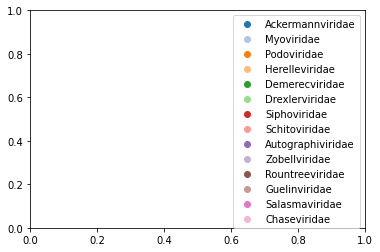

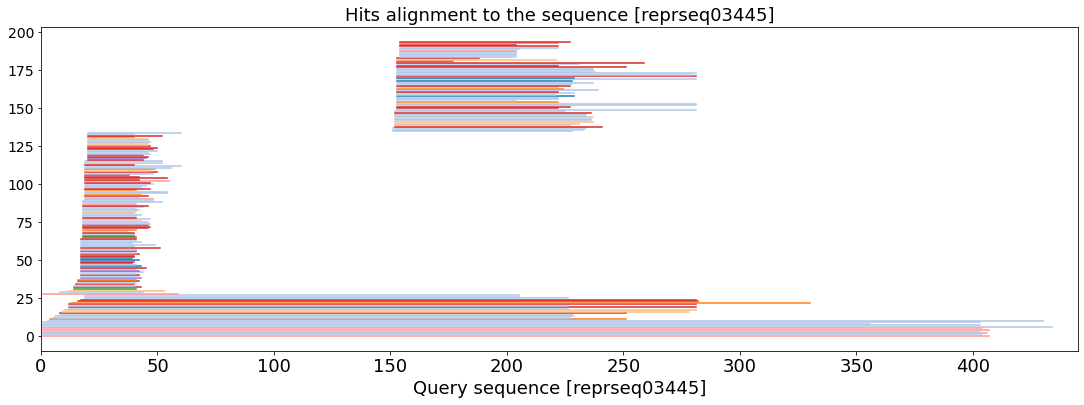

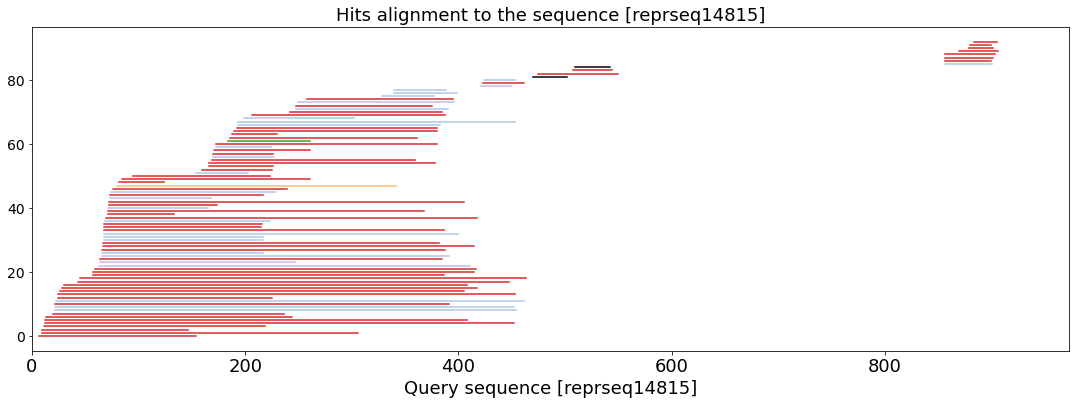

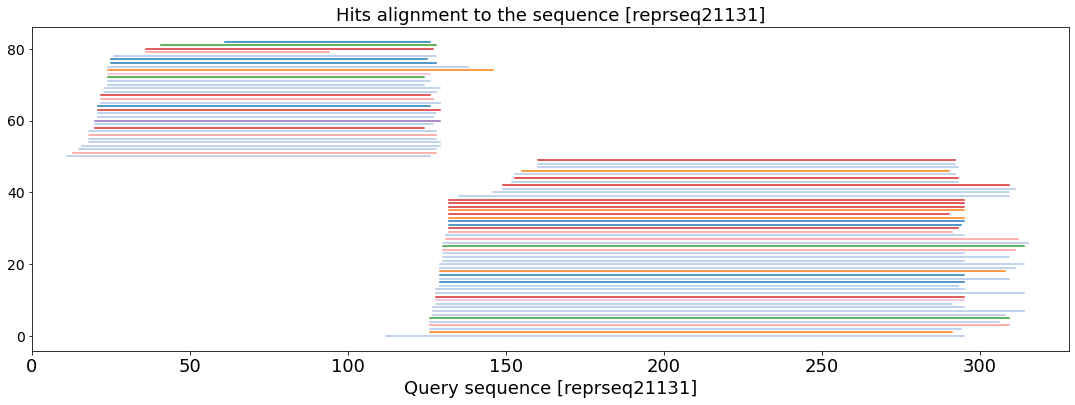

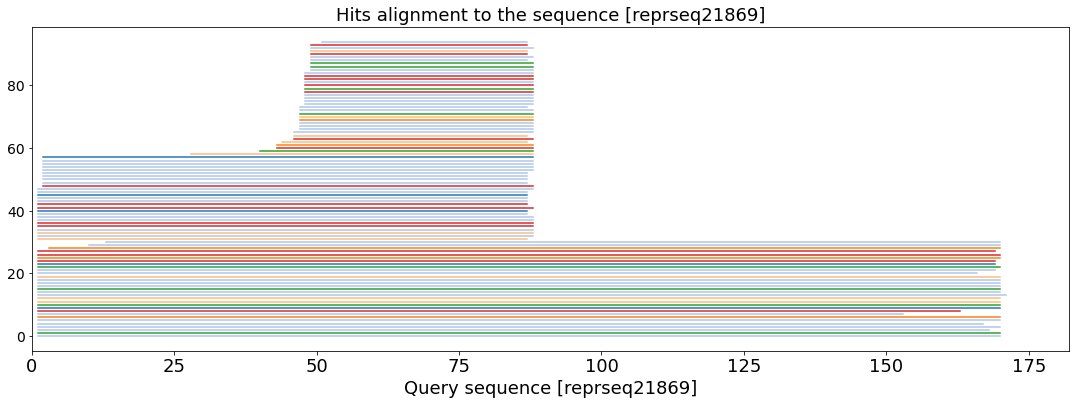

In [69]:
# plot qECF aln, order by cluster, color by taxa
plot_alignment_selected_families(workdir_path, selected_reprseq_data, selected_features_data, unique_labels,
                                 save_figure=False)